**Load Codes**

In [1]:
import pandas as pd
import requests
import pathlib
import numpy as np

with open("../data/ads_codes.txt") as f:
    text = f.read()
pairs = np.array([s.split() for s in text.split(",")])

codes, ligands = pairs.T

print(codes)
print(len(codes))
print(ligands)
print(ligands[0])


['1G9V' '1GKC' '1GM8' '1GPK' '1HNN' '1HP0' '1HQ2' '1HVY' '1HWI' '1HWW'
 '1IA1' '1IG3' '1J3J' '1JD0' '1JJE' '1JLA' '1K3U' '1KE5' '1KZK' '1L2S'
 '1L7F' '1LPZ' '1LRH' '1M2Z' '1MEH' '1MMV' '1MZC' '1N1M' '1N2J' '1N2V'
 '1N46' '1NAV' '1OF1' '1OF6' '1OPK' '1OQ5' '1OWE' '1OYT' '1P2Y' '1P62'
 '1PMN' '1Q1G' '1Q41' '1Q4G' '1R1H' '1R55' '1R58' '1R9O' '1S19' '1S3V'
 '1SG0' '1SJ0' '1SQ5' '1SQN' '1T40' '1T46' '1T9B' '1TOW' '1TT1' '1TZ8'
 '1U1C' '1U4D' '1UML' '1UNL' '1UOU' '1V0P' '1V48' '1V4S' '1VCJ' '1W1P'
 '1W2G' '1X8X' '1XM6' '1XOQ' '1XOZ' '1Y6B' '1YGC' '1YQY' '1YV3' '1YVF'
 '1YWR' '1Z95' '2BM2' '2BR1' '2BSM']
85
['RQ3' 'NFH' 'SOX' 'HUP' 'SKF' 'AD3' 'PH2' 'D16' '115' 'SWA' 'TQ3' 'VIB'
 'CP6' 'AZM' 'BYS' 'TNK' 'IAD' 'LS1' 'JE2' 'STC' 'BCZ' 'CMB' 'NLA' 'DEX'
 'MOA' '3AR' 'BNE' 'A3M' 'PAF' 'BDI' 'PFA' 'IH5' 'SCT' 'DTY' 'P16' 'CEL'
 '675' 'FSN' 'NCT' 'GEO' '984' 'MTI' 'IXM' 'BFL' 'BIR' '097' 'AO5' 'FLP'
 'MC9' 'TQD' 'STL' 'E4D' 'PAU' 'NDR' 'ID5' 'STI' '1CS' 'CRZ' 'KAI' 'DES'
 'BAU' 'DBQ' 'FR4' 'RRC' 'C

*

In [2]:
RAW = pathlib.Path("../data/RAW_PDB")

for c in codes:
    if(not (RAW / f"{c}.pdb").exists()):
        r = requests.get(f"https://files.rcsb.org/download/{c}.pdb")
        (RAW / f"{c}.pdb").write_text(r.text)


In [3]:
print(len(list(RAW.glob("*.pdb"))))

85


**1G9V in pymol** 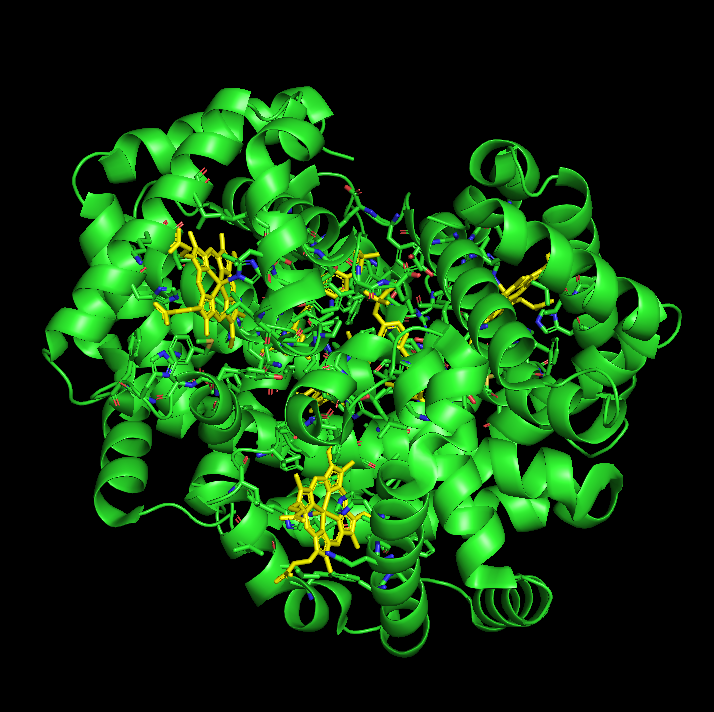



We note that there are multiple copies of the ligand in this example; 

In [4]:
import pymol2

#this code removes multiple ligand cases. as well as isolates the ligand

for code, lig in zip(codes, ligands):
    p1 = pymol2.PyMOL()
    p1.start()
    cmd = p1.cmd
    cmd.load(f"../data/RAW_PDB/{code}.pdb", "struct")
    chains = cmd.get_chains(f"resn {lig} and not polymer")
    if not chains:
        print(code, "NO LIGAND FOUND")
        p1.stop()
        continue
    chain = chains[0]
    cmd.save(f"../data/PREP/{code}_protein.pdb", "polymer")              # <- no chain filter
    cmd.save(f"../data/PREP/{code}_ligand.pdb", f"resn {lig} and chain {chain} and not polymer")
    p1.stop()

In [ ]:
!conda install -c conda-forge pymol-open-source -y